# 03. Détection des candidats (phase 3)

Chaîne : seuillage des structures denses dans le masque pulmonaire, transformée de distance, marqueurs (maxima locaux), watershed, troncature en boule autour du pic, filtrage par squelette et par taille. Paramètres figés dans `config.yaml`.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "results"
pd.set_option("display.width", 200)
import yaml
print(yaml.safe_load((ROOT / 'config.yaml').read_text(encoding='utf-8')))

{'resample_mm': 1.0, 'thr': -320, 'r_open': 2, 'r_close': 8, 'candidate_intensity_threshold': -320, 'candidate_min_seed_radius_mm': 1.2, 'candidate_min_distance_mm': 8.0, 'candidate_min_diameter_mm': 3.0, 'candidate_max_diameter_mm': 30.0, 'candidate_max_skeleton_ratio': 3.0, 'candidate_max_branch_points': 3, 'morphology_gradient_radius': 1, 'morphology_tophat_radius': 3, 'candidate_opening_radius': 0, 'candidate_truncate_factor': 1.3}


## Réglage des paramètres (split `dev` uniquement)

Chaque essai est consigné dans `results/tests_detection.csv`. La ligne sans paramètre est le baseline de départ (rappel 0,48). Les nodules manqués par le baseline étaient rejetés par le filtre squelette (nodules collés à un vaisseau), sans graine (`min_distance_mm` trop grand) ou sous le seuil d'intensité.

In [2]:
tests = pd.read_csv(RESULTS / 'tests_detection.csv')
display(tests.sort_values('rappel', ascending=False))

,nodules,retrouves,rappel,faux_positifs_par_scan,candidats_par_scan,temps_s,min_distance_mm,intensity_threshold,opening_radius,max_skeleton_ratio,max_branch_points,truncate_factor,min_seed_radius_mm
20,25,23,0.92,264.9,266.5,58,8.0,-400.0,NaN,3.0,3.0,1.3,1.2
19,25,22,0.88,215.6,217.1,58,8.0,NaN,NaN,3.0,3.0,1.3,1.2
21,25,22,0.88,301.8,303.3,56,8.0,-400.0,NaN,3.0,3.0,1.6,1.2
15,25,21,0.84,242.4,243.8,52,8.0,NaN,NaN,3.0,3.0,1.6,1.2
17,25,18,0.72,161.9,163.1,54,8.0,-400.0,NaN,3.0,3.0,1.6,1.5
18,25,17,0.68,137.3,138.4,55,8.0,NaN,NaN,3.0,3.0,1.3,1.5
14,25,16,0.64,136.9,138.0,54,8.0,NaN,NaN,3.0,3.0,1.6,1.5
16,25,16,0.64,136.5,137.6,52,8.0,NaN,NaN,2.0,1.0,1.6,1.5
9,25,16,0.64,226.1,227.2,55,6.0,NaN,NaN,3.0,3.0,1.6,1.5
5,25,13,0.52,274.7,275.6,57,4.0,-450.0,2.0,NaN,NaN,NaN,NaN


## Résultats par scan et par split

In [3]:
ev = pd.read_csv(RESULTS / 'detection_eval.csv')
summary = ev.groupby('split').agg(nodules=('nodules','sum'), retrouves=('nodules_retrouves','sum'),
                                   fp_par_scan=('faux_positifs','mean'))
summary['rappel'] = summary.retrouves / summary.nodules
display(summary)
display(ev[['seriesuid','split','nodules','nodules_retrouves','candidats','faux_positifs']].assign(seriesuid=lambda d: d.seriesuid.str[-8:]))

,nodules,retrouves,fp_par_scan,rappel
split,,,,
dev,25,22,215.6,0.880000
test,19,11,221.7,0.578947


,seriesuid,split,nodules,nodules_retrouves,candidats,faux_positifs
0,48741492,dev,1,1,256,255
1,71755354,dev,1,1,366,365
2,78348912,dev,1,1,201,200
3,61297097,dev,2,2,275,273
4,78408762,dev,1,1,226,225
5,97754952,dev,4,4,188,184
6,13996730,dev,3,3,213,210
7,07114231,dev,2,0,146,146
8,89983845,dev,1,1,240,239
9,46860596,dev,1,0,151,151


Le rappel sur `test` est nettement plus bas que sur `dev` (où les paramètres ont été réglés) : le réglage sur 15 scans ne généralise que partiellement.

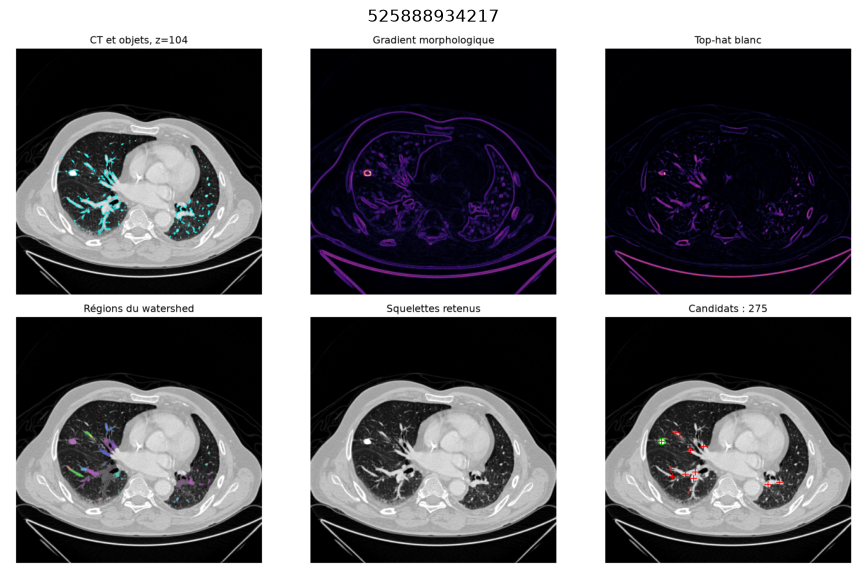

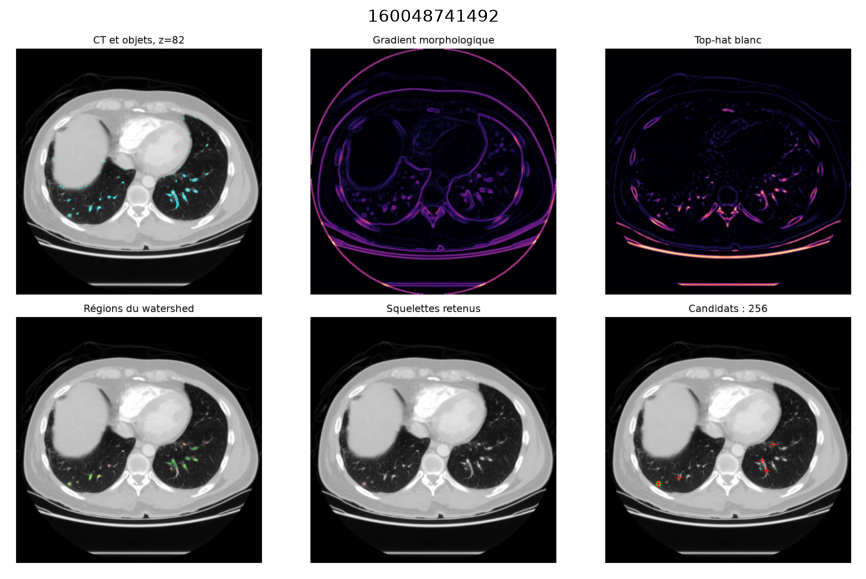

In [4]:
fig_dir = RESULTS / 'detection_figures'
for path in sorted(fig_dir.glob('*.png'))[:2]:
    plt.figure(figsize=(12, 7)); plt.imshow(mpimg.imread(path)); plt.axis('off'); plt.title(path.stem[-12:]); plt.show()